# 3-fish recording: EODs that Denis assigns correctly and my model (BEM conductivities) does not

Test set: 100 random EODs from the good frames (mask QC and SLEAP; `numpy.random.default_rng(0)`), as in the skin test of
`EOD_assignment_3_fish_conductivities.ipynb`. My model with the BEM conductivities (interior 100 × water, skin 0.05 × water over
0.005 cm = 1e-3 S/cm²), shape-only rule, both sink positions; Denis' latest run (3-fish electrode file, no refractory step).
The emitter is fish 0 (smallest, SLEAP C).

For each EOD where Denis picks fish 0 and my model does not:
- **tank**: video frame, ZEUS masks, my midlines and heads, Denis' midline (his point currents) and the SLEAP keypoints, electrodes
  with pair number and polarity;
- **voltages at the 10 electrode pairs**, one row per fish as the candidate emitter: the recorded window (scaled to max |v| = 1 at the
  peak), my model pattern (scaled to max |v| = 1, **times −1**: the sign that fish 0's model has relative to the recorded peak in 99% of
  good-frame EODs, see the last section) and Denis' predicted pattern (scaled to max |v| = 1, with the sign his similarity uses), both
  times the recorded EOD waveform. The shape-only rule instead lets the sign of my model flip to fit.

In [1]:
import os, pickle, subprocess
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mask_metrics as mm                         # ZEUS crop unpacking (sets the Agg backend...)
%matplotlib inline
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from scipy.sparse.linalg import splu
from compute_electric_field import multipole_sources, build_multipole_b, occupancy_field, build_A_shell, unflatten_to_grid, gammas
from midline_methods import fish_midline_with_head
from eod_assign import load_electrode_pairs, peak_pattern, rank1_pattern, pair_voltages, compare_patterns

DATA = 'data/3_fish_silent'
EOD_CSV = f'{DATA}/Assigned_Data_3fish_2024-10-15T14_12_25.csv'
TRACK_PKL = f'{DATA}/elephantnose_20241015T141225_tracking_final.pkl'
VIDEO = f'{DATA}/video2024-10-15T14_12_25.avi'
ELECTRODES_CSV = 'data/electrodes/electrodes_signed_px_coord_3-fish.csv'
QC = 'results/eod_ground_truth_3fish'                                              # frame groups (EOD_assignment_3_fish_silent.ipynb)
DENIS_DIR = 'results/eod_assignment_3_fish_silent'                                 # Denis' latest run
DENIS_PKL = f'{DENIS_DIR}/electrodes_3-fish/Assigned_Data_3fish_2024-10-15T14_12_25.pkl'
OUT = f'{QC}/conductivities/examples_denis_right_bem_wrong'
os.makedirs(OUT, exist_ok=True)

FISH, EMITTER = (0, 1, 2), 0
FISH_COLOR = {0: '#E0B000', 1: '#D45087', 2: '#2E8B57'}   # review-reel colours: yellow, pink, green
PX_PER_CM = 912 / 60                            # Denis' pixel2cm
FS = 50000.0                                    # electrode sampling rate (Hz)
N, n_poles = 150, 100
h = 1.0 / (N - 1)
CELL_CM = (912 - 1) / (N - 1) / PX_PER_CM       # grid spacing (cm)
SKIN_CM, LAMBDA_CM = 0.005, 1e-4 / 1e-3         # BEM skin: 0.005 cm thick, as resistive as 0.1 cm of water
BEM = dict(sigma_water=1.0, eps_water=0.0, sigma_interior=100.0, eps_interior=0.0,
           sigma_skin=1 / (LAMBDA_CM / SKIN_CM + 1 / 100.0), eps_skin=0.0)
DELTA_H = SKIN_CM / CELL_CM
SINKS = (0.0, 0.05)
SINK_NAME = {0.0: 'sink at tail tip', 0.05: 'sink 5% from tail tip'}
N_TEST, SEED, N_WORKERS = 100, 0, 6
OUTLINE = [pe.withStroke(linewidth=3, foreground='k')]

In [2]:
df_eod = pd.read_csv(EOD_CSV)
trace_cols = {p: [c for c in df_eod.columns if c.startswith(f'electrode_{p}_t_')]
              for p in sorted({int(c.split('_')[1]) for c in df_eod.columns if c.startswith('electrode_')})}

def recorded_pair_traces(row, pair_ids):
    '''(n_pairs, n_samp) recorded voltages of one df_eod row, each pair demeaned.'''
    V = np.stack([row[trace_cols[p]].to_numpy(float) for p in pair_ids])
    return V - np.nanmean(V, axis=1, keepdims=True)

with open(TRACK_PKL, 'rb') as f:
    trk = pickle.load(f)
frames, P, fps = trk['frames'], trk['shape'][0], trk['fps']

def frame_masks(k):
    '''(n_fish, P, P) full-frame bool masks of frame k, indexed by fish label (empty where a fish has no mask).'''
    m = np.zeros((len(FISH), P, P), bool)
    for l, p, (y0, y1, x0, x1) in zip(frames[k]['labels'], frames[k]['masks'], frames[k]['boxes']):
        if l in FISH: m[l, y0:y1, x0:x1] = mm.unpack_crop(p, (y0, y1, x0, x1))
    return m

def video_frame(k):
    '''Grayscale (P, P) frame k of the raw video (ffmpeg).'''
    out = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{k / fps:.4f}', '-i', VIDEO, '-frames:v', '1', '-f', 'rawvideo',
                          '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(out, np.uint8).reshape(P, P)

pairs = load_electrode_pairs(ELECTRODES_CSV, P)        # [(pair id, + point, - point)] in (row, col) / (P - 1)
pair_ids = [pid for pid, _, _ in pairs]
qc = pd.read_csv(f'{QC}/eod_qc_status.csv', index_col='row')
den = pd.read_pickle(DENIS_PKL)                         # per EOD: keypoints, point currents, predicted patterns (cm), choice
den_sum = pd.read_csv(f'{DENIS_DIR}/eod_assignment_summary.csv')   # + distance to the nearest fish / electrode (cm)
assert len(den) == len(den_sum) == len(df_eod) == len(qc)
assert (den.Frame.to_numpy() == df_eod.Frame.to_numpy()).all() and (den_sum.Frame.to_numpy() == df_eod.Frame.to_numpy()).all()
good = np.flatnonzero(qc.analysed.to_numpy())
test = np.sort(np.random.default_rng(SEED).choice(good, N_TEST, replace=False))
print(f'{N_TEST} test EODs from {len(good)} good-frame EODs')

100 test EODs from 6938 good-frame EODs


## My model on the test EODs (BEM conductivities)

Same solve as `EOD_assignment_3_fish_conductivities.ipynb`: each fish in turn emits unit current along its midline, the other two
are bodies, one LU factorization per fish and both sink positions.

In [3]:
def fish_midlines(fm):
    '''Midline (n_poles + 1, 2) in tank coords, tail -> head, of every fish; None where the mask is empty or the fit fails.'''
    out = []
    for m in fm:
        try:
            mid = fish_midline_with_head(m, n_ctrl=n_poles + 1)['midline'] if m.any() else None
            out.append(mid if mid is not None and np.isfinite(mid).all() else None)
        except Exception:
            out.append(None)
    return out

def solve_sinks(A, bs, pin=0):
    '''solve_potential for several current layouts bs with one LU factorization (same pinned node and gauge).'''
    M = (-A).tolil(); M[pin, :] = 0; M[pin, pin] = 1
    lu = splu(M.tocsc()); out = []
    for b in bs:
        rhs = np.asarray(b).ravel().astype(complex); rhs[pin] = 0
        phi = lu.solve(rhs); out.append(phi - phi.mean())
    return out

GAM = gammas(0.0, **BEM)

def model_voltages(i):
    '''{sink: unit-current pair voltages (n_fish, n_pairs)} of EOD row i, BEM conductivities.'''
    fm = frame_masks(int(df_eod.Frame[i])); mids = fish_midlines(fm)
    u = {s: np.full((len(FISH), len(pairs)), np.nan) for s in SINKS}
    for f in FISH:
        if mids[f] is None: continue
        bs = [build_multipole_b(*multipole_sources(mids[f], I0=1.0, sink_frac=s), h, N) for s in SINKS]
        for s, phi in zip(SINKS, solve_sinks(build_A_shell(occupancy_field(fm, N, skip=f), N, DELTA_H, *GAM), bs)):
            u[s][f] = pair_voltages(unflatten_to_grid(phi, N).real, pairs, N)
    return u

with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
    Um = dict(zip(test, pool.map(model_voltages, test.tolist(), chunksize=2)))
R = {i: peak_pattern(recorded_pair_traces(df_eod.loc[i], pair_ids))[0] for i in test}
D = {(i, s): np.array([compare_patterns(m, R[i])[0] for m in Um[i][s]]) for i in test for s in SINKS}
tab = pd.DataFrame({'frame': df_eod.Frame[test].to_numpy(),
                    **{f'mine, {SINK_NAME[s]}': [int(D[i, s].argmin()) for i in test] for s in SINKS},
                    "Denis' choice": den.discharging_fish[test].to_numpy()}, index=pd.Index(test, name='row'))
print({c: int((tab[c] == EMITTER).sum()) for c in tab.columns[1:3]}, "| Denis:", int((tab["Denis' choice"] == 'C').sum()), 'of', N_TEST)
ex = tab[(tab["Denis' choice"] == 'C') & ((tab.iloc[:, 1] != EMITTER) | (tab.iloc[:, 2] != EMITTER))]
display(ex)

{'mine, sink at tail tip': 91, 'mine, sink 5% from tail tip': 91} | Denis: 93 of 100


,frame,"mine, sink at tail tip","mine, sink 5% from tail tip",Denis' choice
row,,,,
73,80,1,1,C
8865,13216,2,2,C
11784,17113,2,2,C


## The examples

Denis names the fish by length (A longest, C smallest = fish 0); each of his fish is matched to the mask holding most of its confident
keypoints. Row labels: my distance `d` (smaller = better) with the sign free (the shape-only rule) and with the sign fixed (model × −1),
for both sinks, and Denis' similarity (cosine with sign, larger = better). ◀ marks each pipeline's choice (mine: sink at tail tip,
sign free).

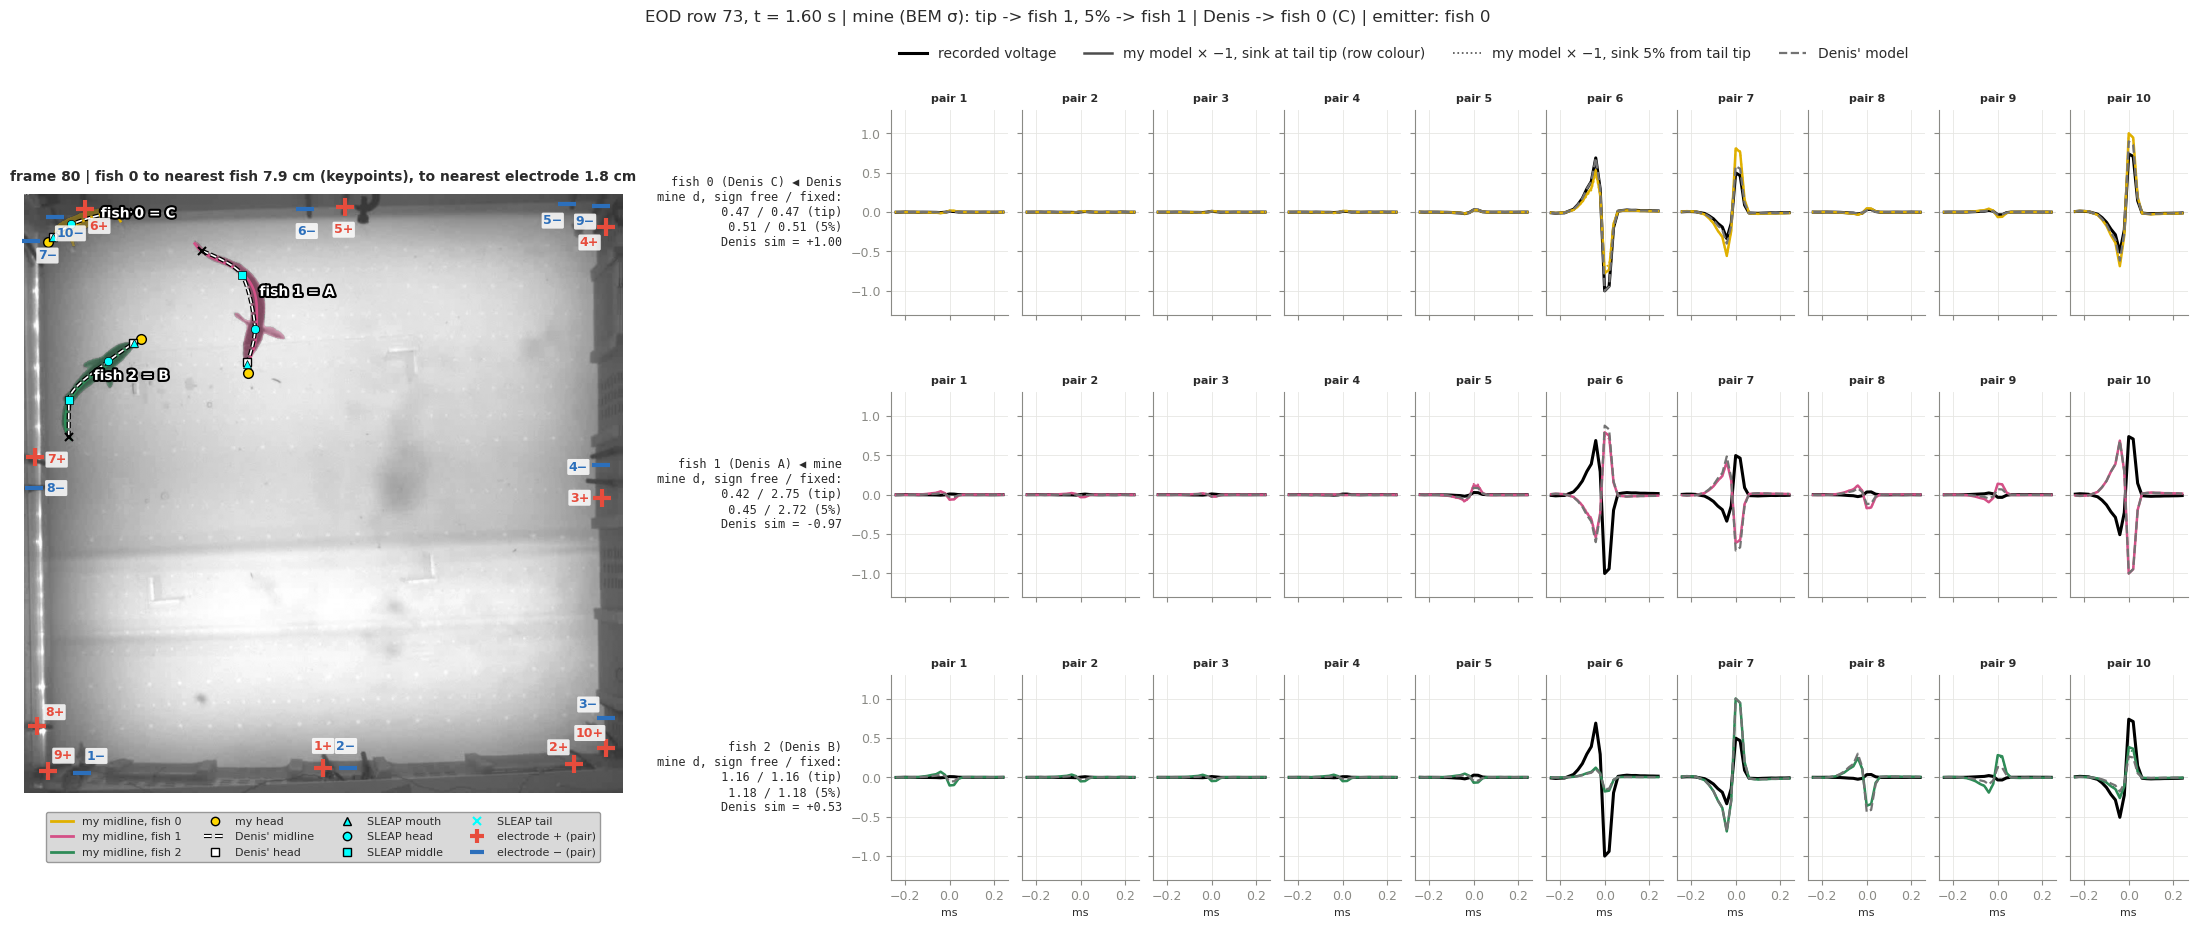

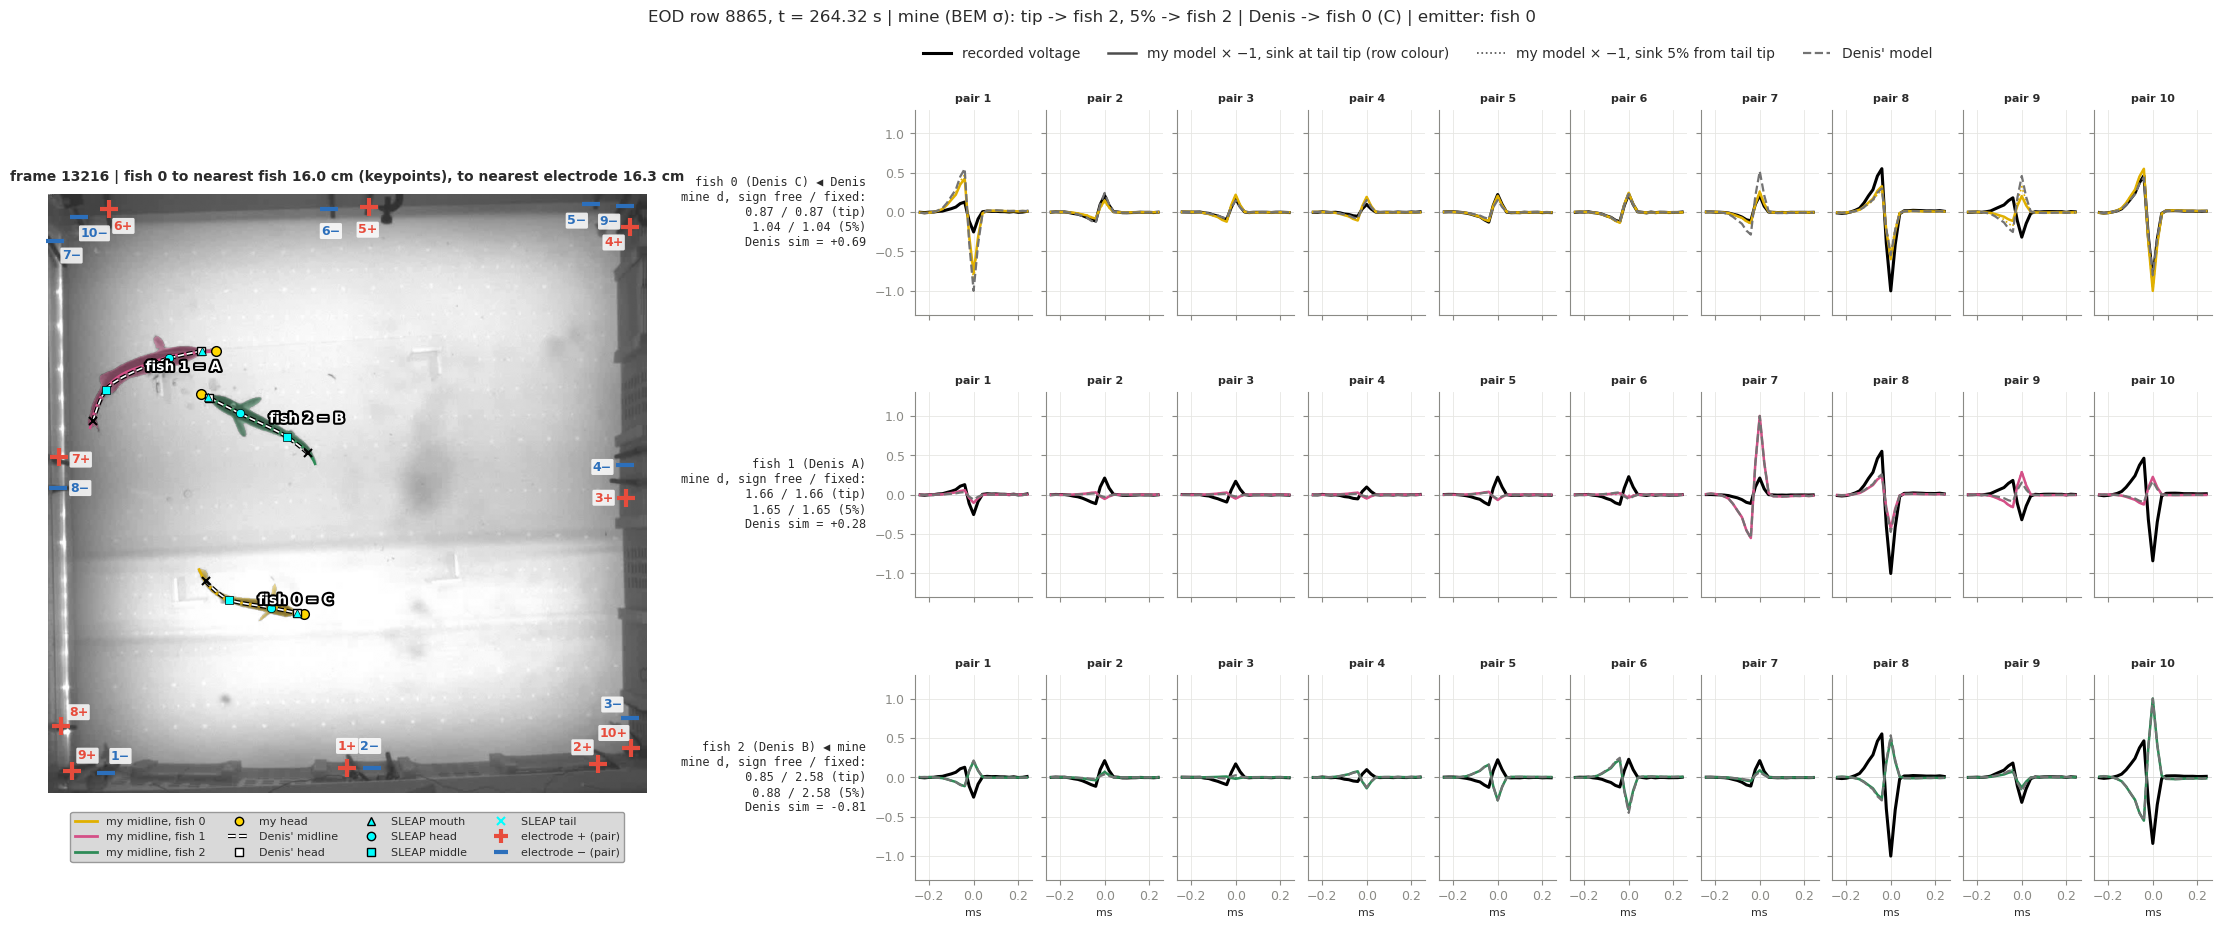

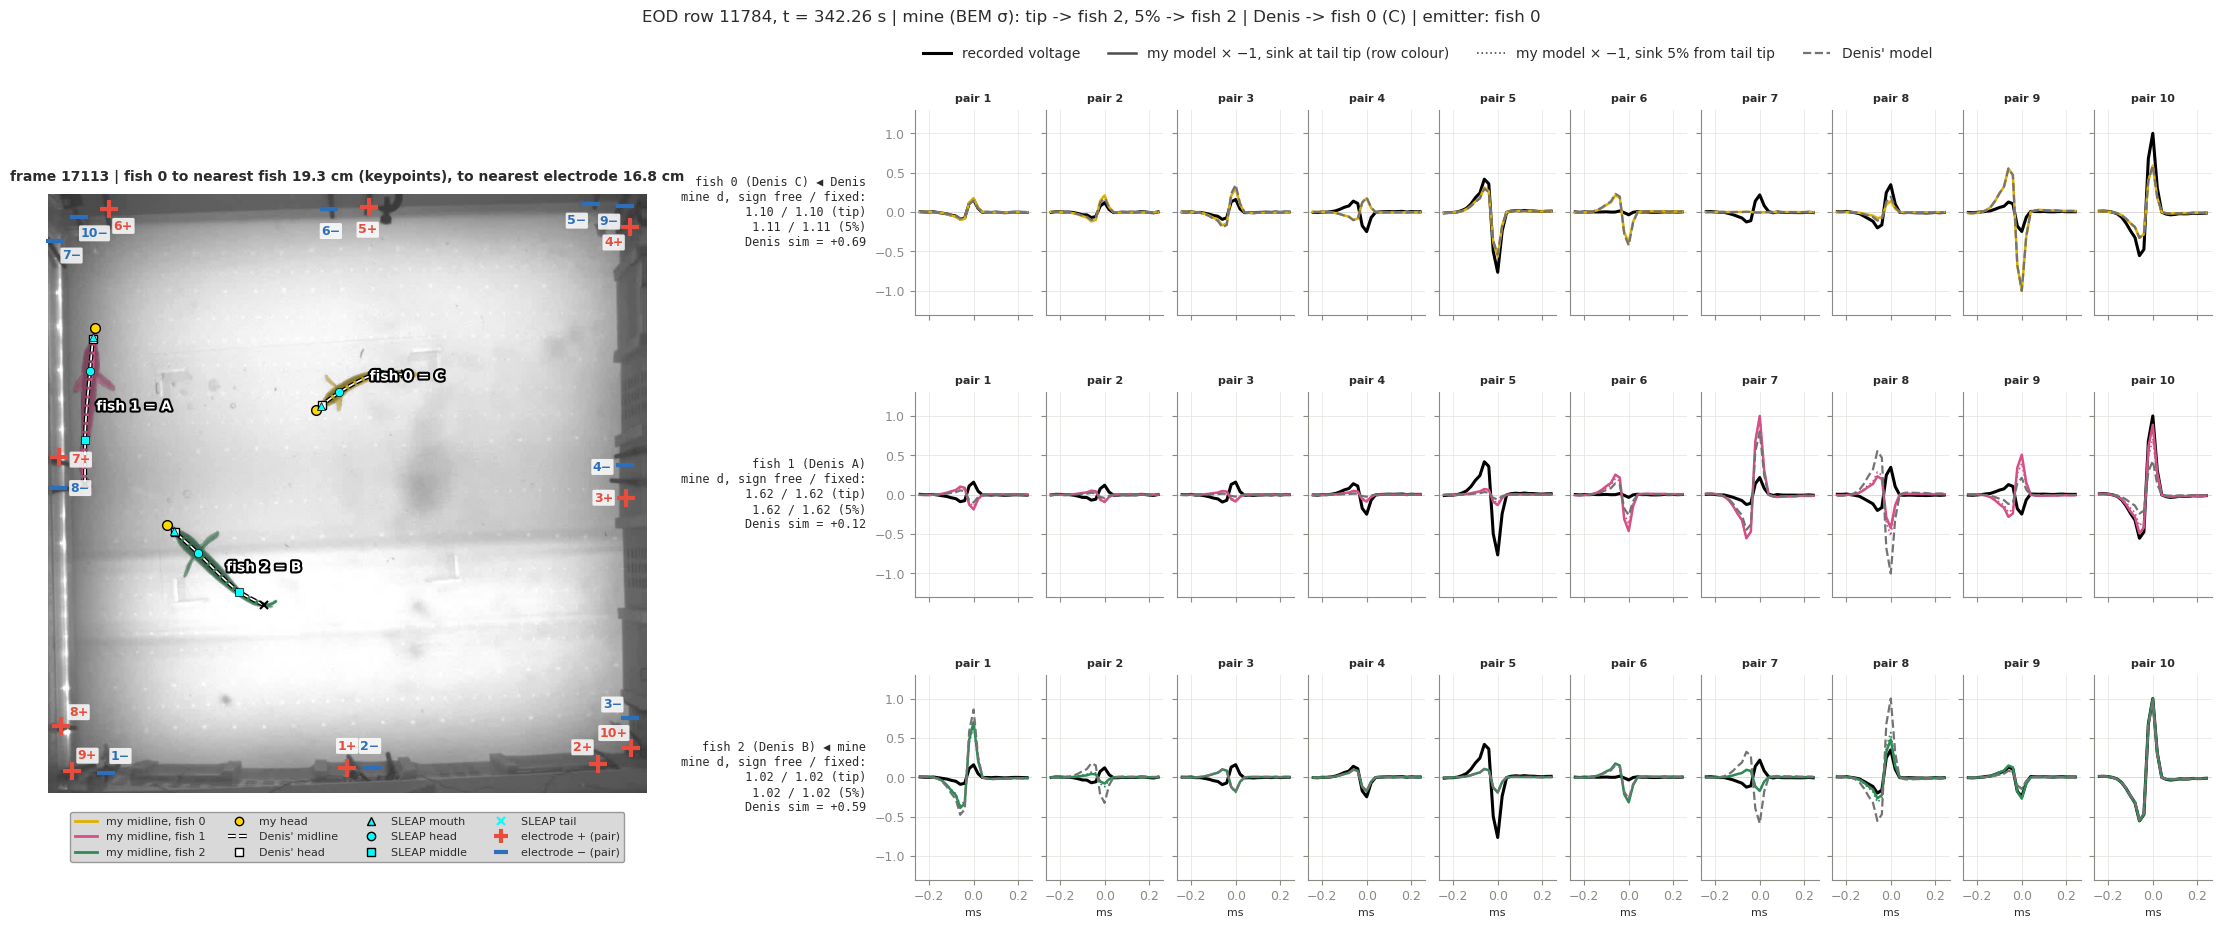

In [4]:
def mask_of(d, X, fm, min_score=0.5):
    '''Mask label holding most confident keypoints of Denis' fish X in row d (-1 if none is on a mask).'''
    votes = []
    for kp in ('mouth', 'head', 'middle', 'tail'):
        if not d[f'score_{kp}_{X}'] > min_score: continue
        x, y = np.round(np.asarray(d[f'{kp}_{X}']) * PX_PER_CM).astype(int)
        if 0 <= x < P and 0 <= y < P: votes += [f for f in FISH if fm[f][y, x]]
    return max(set(votes), key=votes.count) if votes else -1

def plot_example(i):
    k = int(df_eod.Frame[i]); fm = frame_masks(k); mids = fish_midlines(fm); dp = den.loc[i]
    letter = {mask_of(dp, X, fm): X for X in 'ABC'}                         # mask label -> Denis' fish
    assert sorted(letter) == list(FISH), letter
    V = recorded_pair_traces(df_eod.loc[i], pair_ids); r, ts = peak_pattern(V); rmax = np.abs(r).max()
    w = rank1_pattern(V)[1]; w = w / w[ts]                                    # EOD waveform, 1 at the peak sample
    t_ms = (np.arange(V.shape[1]) - V.shape[1] // 2) / FS * 1e3
    sigma = np.sign(np.asarray(dp.recorded_PTP) @ r)                          # Denis' peak-to-peak sign -> peak-sample sign
    mine = {s: int(D[i, s].argmin()) for s in SINKS}
    den_f = {v: kk for kk, v in letter.items()}[dp.discharging_fish]

    fig = plt.figure(figsize=(28, 10))
    gs = fig.add_gridspec(3, 12, width_ratios=[5.2, 2.0] + [1] * 10, wspace=0.08, hspace=0.38)
    a = fig.add_subplot(gs[:, 0])
    a.imshow(video_frame(k), cmap='gray')
    over = np.zeros((P, P, 4))
    for f in FISH:
        over[fm[f]] = to_rgba(FISH_COLOR[f], 0.4)
        if mids[f] is not None:
            mid = mids[f] * (P - 1)                                           # (row, col), tail -> head
            a.plot(mid[:, 1], mid[:, 0], color=FISH_COLOR[f], lw=1.8)
            a.plot(mid[-1, 1], mid[-1, 0], 'o', color='gold', mec='k', ms=7)
        X = letter[f]
        dm = np.asarray(dp[f'currents_locations_{X}']) * PX_PER_CM             # (x, y) px, tail -> mouth
        a.plot(dm[:, 0], dm[:, 1], color='w', lw=1.2, ls='--', path_effects=OUTLINE)
        a.plot(dm[-1, 0], dm[-1, 1], 's', color='w', mec='k', ms=6)
        for kp, mk in (('mouth', '^'), ('head', 'o'), ('middle', 's'), ('tail', 'x')):
            x, y = np.asarray(dp[f'{kp}_{X}']) * PX_PER_CM
            a.plot(x, y, mk, color='cyan', mec='k', ms=6, mew=1.5 if mk == 'x' else 0.5)
        a.text(*dm[len(dm) // 2], f'  fish {f} = {X}', color='w', fontsize=10, fontweight='bold', path_effects=OUTLINE)
    a.imshow(over); a.set_axis_off()
    for pid, pp, pm in pairs:                                                 # electrodes, labelled pair + polarity
        for pt, sgn, col, mk in ((pp, '+', '#E74C3C', '+'), (pm, '−', '#2C6FBB', '_')):
            y, x = pt * (P - 1)
            a.plot(x, y, mk, color=col, ms=13, mew=3)
            off = np.array([P / 2 - x, P / 2 - y]); off = 34 * off / np.linalg.norm(off)
            a.text(x + off[0], y + off[1], f'{pid}{sgn}', color=col, fontsize=9, fontweight='bold', ha='center', va='center',
                   bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.85))
    a.set(xlim=(-10, P + 10), ylim=(P + 10, -10))
    a.set_title(f"frame {k} | fish 0 to nearest fish {den_sum.dist_fish_cm[i]:.1f} cm (keypoints), "
                f"to nearest electrode {den_sum.dist_electrode_cm[i]:.1f} cm", fontsize=10)
    a.legend(handles=[Line2D([], [], color=FISH_COLOR[f], lw=2, label=f'my midline, fish {f}') for f in FISH] +
                     [Line2D([], [], marker='o', color='gold', mec='k', ls='', label='my head'),
                      Line2D([], [], color='w', lw=1.5, ls='--', path_effects=OUTLINE, label="Denis' midline"),
                      Line2D([], [], marker='s', color='w', mec='k', ls='', label="Denis' head"),
                      Line2D([], [], marker='^', color='cyan', mec='k', ls='', label='SLEAP mouth'),
                      Line2D([], [], marker='o', color='cyan', mec='k', ls='', label='SLEAP head'),
                      Line2D([], [], marker='s', color='cyan', mec='k', ls='', label='SLEAP middle'),
                      Line2D([], [], marker='x', color='cyan', mec='cyan', mew=1.5, ls='', label='SLEAP tail'),
                      Line2D([], [], marker='+', color='#E74C3C', ms=10, mew=3, ls='', label='electrode + (pair)'),
                      Line2D([], [], marker='_', color='#2C6FBB', ms=10, mew=3, ls='', label='electrode − (pair)')],
             loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=4, fontsize=8, frameon=True, facecolor='0.85',
             edgecolor='0.6', framealpha=1)

    for f in FISH:
        X = letter[f]
        mine_u, d_free, d_fix = {}, {}, {}
        for s in SINKS:
            u = -Um[i][s][f] / np.abs(Um[i][s][f]).max(); mine_u[s] = u                       # fixed sign: model x -1
            d_free[s] = compare_patterns(Um[i][s][f], r)[0]; d_fix[s] = np.linalg.norm(u - r / rmax)
        pd_hat = sigma * np.asarray(dp[f'normalized_predicted_PTP_{X}']); pd_hat = pd_hat / np.abs(pd_hat).max()
        lab = (f"fish {f} (Denis {X})" + (' ◀ mine' if mine[0.0] == f else '') + (' ◀ Denis' if den_f == f else '') +
               '\nmine d, sign free / fixed:\n' +
               '\n'.join(f"  {d_free[s]:.2f} / {d_fix[s]:.2f} ({'tip' if s == 0 else '5%'})" for s in SINKS) +
               f"\nDenis sim = {dp[f'similarity_{X}']:+.2f}")
        for kk, pid in enumerate(pair_ids):
            ax = fig.add_subplot(gs[f, 2 + kk])
            ax.axhline(0, color='0.85', lw=0.6)
            ax.plot(t_ms, V[kk] / rmax, color='k', lw=2.2)
            ax.plot(t_ms, mine_u[0.0][kk] * w, color=FISH_COLOR[f], lw=1.8)
            ax.plot(t_ms, mine_u[0.05][kk] * w, color=FISH_COLOR[f], lw=1.2, ls=':')
            ax.plot(t_ms, pd_hat[kk] * w, color='0.45', lw=1.6, ls='--')
            ax.set_ylim(-1.3, 1.3); ax.set_title(f'pair {pid}', fontsize=8)
            if kk: ax.set_yticklabels([])
            else: ax.set_ylabel(lab, fontsize=8.5, rotation=0, ha='right', va='center', labelpad=6, family='monospace')
            if f < 2: ax.set_xticklabels([])
            else: ax.set_xlabel('ms', fontsize=8)
    fig.suptitle(f"EOD row {i}, t = {df_eod.RelativeTime[i]:.2f} s | mine (BEM σ): tip -> fish {mine[0.0]}, 5% -> fish {mine[0.05]} | "
                 f"Denis -> fish {den_f} ({dp.discharging_fish}) | emitter: fish 0", fontsize=12)
    fig.legend(handles=[Line2D([], [], color='k', lw=2.2, label='recorded voltage'),
                        Line2D([], [], color='0.3', lw=1.8, label='my model × −1, sink at tail tip (row colour)'),
                        Line2D([], [], color='0.3', lw=1.2, ls=':', label='my model × −1, sink 5% from tail tip'),
                        Line2D([], [], color='0.45', lw=1.6, ls='--', label="Denis' model")],
               loc='upper center', bbox_to_anchor=(0.62, 0.955), ncol=4, fontsize=10, frameon=False)
    fig.savefig(f"{OUT}/eod{i}_frame{k}.png", dpi=100, bbox_inches='tight'); plt.show()

for i in ex.index: plot_example(i)

## The sign of the model

My unit-current model has a definite sign (sink at the tail, sources towards the head), and the recorded peak pattern is taken at the
sample where |V| peaks, which is the larger phase of the EOD waveform, the same phase every time. So the true emitter's model should
match the recording with the same sign in every EOD. The shape-only rule ignores this: it flips the model's sign whenever that fits
better, so a fish whose pattern matches only upside down can win (rows 73 and 8865 above).

All 6,938 good-frame EODs, previous conductivities (`EOD_assignment_3_fish_silent.ipynb`'s model voltages): how often fish 0's model
has the opposite sign to the recording, and the % correct with the sign free (shape-only rule) or fixed (model × −1).

In [5]:
from eod_assign import normalize_peak
c = pd.read_pickle(f'{QC}/model_voltages_N150_sinks0and0.05_elc5c81b.pkl').loc[qc.index[qc.analysed]]
r = np.stack([normalize_peak(x) for x in c.v_rec])
rows = {}
for s in SINKS:
    U = np.stack(c[f'u_sink{s:g}'])
    a = U / np.abs(U).max(axis=2, keepdims=True)
    d_free = np.minimum(np.linalg.norm(a - r[:, None], axis=2), np.linalg.norm(a + r[:, None], axis=2))
    d_fix = np.linalg.norm(-a - r[:, None], axis=2)
    rows[SINK_NAME[s]] = {"fish 0: model sign opposite to the recording (%)": 100 * np.mean(np.einsum('nfp,np->nf', U, r)[:, 0] < 0),
                          '% correct, sign free (shape-only rule)': 100 * np.mean(d_free.argmin(1) == EMITTER),
                          '% correct, sign fixed (model × −1)': 100 * np.mean(d_fix.argmin(1) == EMITTER)}
t = pd.DataFrame(rows).T
t["Denis' latest run (% correct)"] = 100 * (den.discharging_fish[c.index] == 'C').mean()
display(t.round(2))

,fish 0: model sign opposite to the recording (%),"% correct, sign free (shape-only rule)","% correct, sign fixed (model × −1)",Denis' latest run (% correct)
sink at tail tip,98.98,89.48,94.47,93.89
sink 5% from tail tip,98.82,87.55,93.57,93.89
